# DeviceLayout.jl SingleTransmon: a rectangle transmon with a clawed λ/4 readout, rebuilt in the Quantcore PDK step by step

**Source:** AWS Center for Quantum Computing, **DeviceLayout.jl**, `examples/SingleTransmon/SingleTransmon.jl` and the
docs page `docs/src/examples/singletransmon.md`, with the components `ExampleRectangleTransmon` and
`ExampleClawedMeanderReadout` from `src/schematics/ExamplePDK`, <https://github.com/aws-cqc/DeviceLayout.jl>, **MIT
licence** ("Copyright Amazon.com, Inc. or its affiliates", `LICENSE.md`; depth-1 clone read 2026-11-03 into
`build/external/DeviceLayout.jl`, Julia, never run). We distribute the rebuild under GPL-3.0. Spec:
`docs/designs/devicelayout/singletransmon.md`. Source figure: `docs/src/assets/single_transmon_mesh.png` (the Palace
mesh).

**What the chip is:** a Palace eigenmode example, not a fab layout. A grounded rectangular transmon island
(24 × 620 µm in a 30 µm gap) is read out by a λ/4 meander. The line is shorted at the far end of a 400 µm coupled
section beside a straight 2700 µm feedline (5 µm ground strip), leaves it through a 500 µm leg, meanders (5 turns,
r 50 µm) and ends in a claw that wraps the island's near end. The Palace model has lumped ports at both feedline ends
and airbridges every 300 µm; its targets are 3.370 GHz (qubit) and 5.244 GHz (resonator).

**This notebook rebuilds it in the Quantcore PDK; it is not a replica.** What the rebuild keeps and what the PDK
changes:

| topic | source (DeviceLayout.jl) | this rebuild |
|---|---|---|
| die and frame | a 4 × 3.7 mm Palace domain, no frame | PDK 7.5 mm die with dicing L's, alignment grids, device ID `DL-ST` |
| stack | sapphire (Palace: εr 9.3 / 9.3 / 11.5) | PDK sapphire 650 µm, εr 10.25 |
| qubit | `ExampleRectangleTransmon` (island 24 × 620 µm, 30 µm gap, 12 µm junction gap) | KQC `Swissmon` with short W/E arms and the same island, gaps and claw (the 2 µm claw shield is not drawn) |
| junction | lumped L_J 14.860 nH, C 5.5 fF | Quantcore trilayer junction sized for 4.05 GHz (the source's 3.37 GHz is below the PDK band); R_n ≈ 120 kΩ flagged, not retuned |
| readout | 5000 µm λ/4, 400 µm coupled section, 5 µm strip, 5 meander turns | the same lengths, a qcc hanger on the feedline (`near=`: the coupler stays where it was) |
| feedline ports | lumped ports at the domain edge | two `BondPad`s; **PDK pad rule**: `frame.pad_edge` = 100 µm from the die edge, so the feedline runs die edge to die edge |
| placement | domain centred on the feedline system | **PDK**: the content is centred in the die |
| airbridges | every 300 µm on every path | omitted (KQC's auto bridges across the coupled section shorted to the neighbouring line) |
| cheese | none (a simulation example: no ground holes in `SingleTransmon.jl`) | **PDK band** (`cheese: "auto"`) |
| netlist, LOM, FEM | Palace eigenmodes | our netlist and LOM, Q3D and eigenmode job exports |

## 1 · Setup and the PDK

The notebook runs from the repository root. `_common` holds the table, snapshot and PDK helpers shared by the design
notebooks. `LIVE` follows `QCC_LIVE`: with KLayout open, every change shows up live; with `QCC_LIVE=0` (tests, batch
runs) the snapshots are rendered headless.

In [1]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.circuit.bridges import size_junction
from quantcore_circuits.layouts.registry import trilayer_junction

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/devicelayout")
OUT.mkdir(parents=True, exist_ok=True)

The PDK facts this chip relies on. The frame and the cheese band are drawn by the chip build, the pad rule by `edge=`,
the junction by `trilayer_junction`; the PDK design warnings come out of the DRC.

In [2]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 2 · The die and the frame

The source is a 4 × 3.7 mm simulation domain; the rebuild puts it on the PDK's standard 7.5 mm die, with the
domain's coordinates kept: Designer ≈ source + (870, 500) µm, and the box `(-1750, -1900, 5750, 5600)` is the 7.5 mm
die round the domain. The PDK draws the frame (L dicing markers 1000/0, 3 × 3 alignment grids 1001/0, boundary
100/0) and the device ID `DL-ST` on a free edge. `SingleTransmon.jl` has no ground-plane holes (DemoQPU17 adds them
with `autofill!`; this example does not), so the default `cheese: "auto"` gives the PDK band.

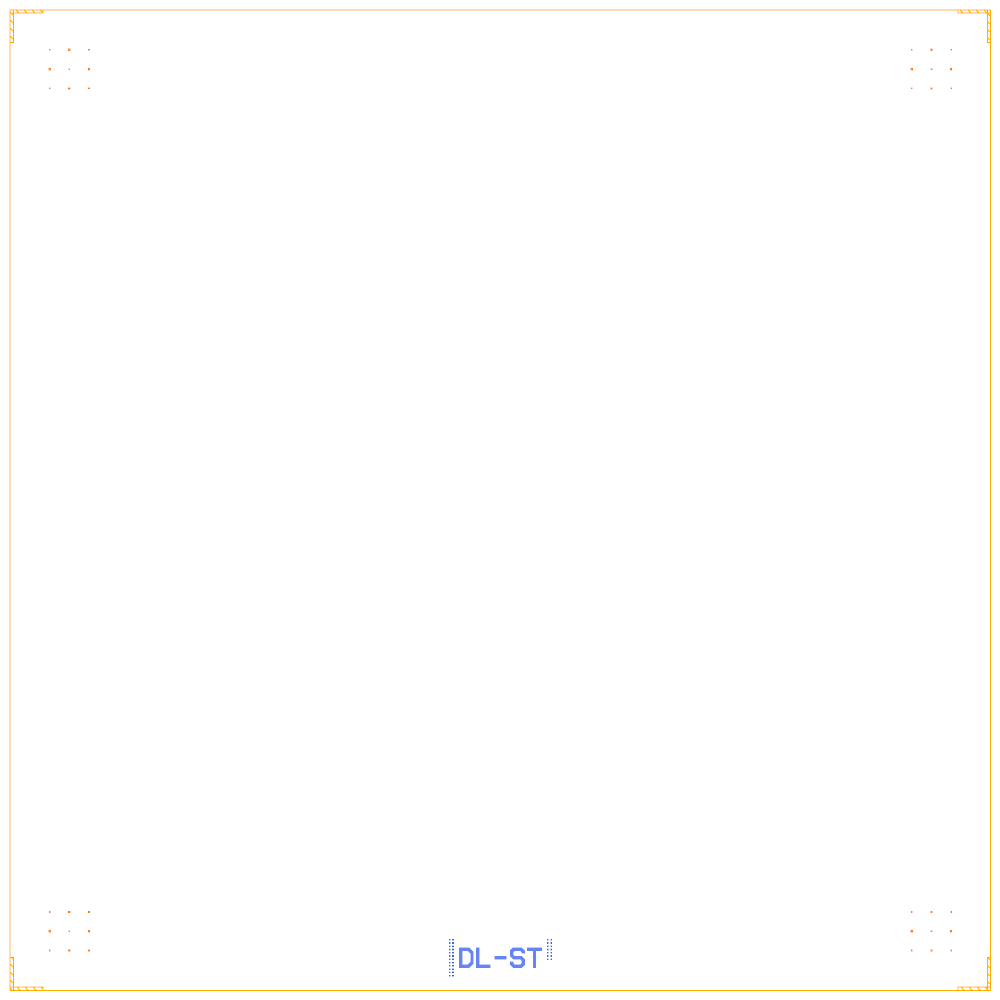

In [3]:
d = Designer("singletransmon", box=(-1750, -1900, 5750, 5600), chip={"name_chip": "DL-ST"}, live=LIVE)
snap(d, OUT / "singletransmon_die.png", size=(1000, 1000), width=360);

## 3 · Pads: the feedline ends

The source has no pads: the feedline ends in Palace lumped ports at its two end points (870, 500) and (870, 3200). The
rebuild terminates it with two small KQC `BondPad`s (200 × 200 µm, 150 µm taper), the south one facing north and the
north one facing south. The PDK puts every bond pad and launcher with the outer edge of its etch **`frame.pad_edge` =
100 µm from the die edge**: `edge="auto"` slides each pad perpendicular to its nearest die edge (here
south and north) until that holds, keeping its x. `pads_md(d)` lists each pad's distance to the nearest edge.

In [4]:
XF, Y0 = 870, 500                                # feedline x and the source's start (source (0, 0) → (870, 500))
PAD = dict(pad_width=200, pad_height=200, taper_length=150, pad_gap=50)
ps = d.add("P_S", "BondPad", at=(XF, Y0), rot=0, edge="auto", **PAD)            # faces north
pn = d.add("P_N", "BondPad", at=(XF, Y0 + 2700), rot=180, edge="auto", **PAD)   # faces south
rebuild(d)
display(Markdown(pads_md(d)))

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| P_S | `BondPad` | s | 100.0 | ✓ |
| P_N | `BondPad` | n | 100.0 | ✓ |

## 4 · Components: the rectangle transmon and its junction

**The junction.** The source's qubit is at 3.37 GHz, below the PDK's 4–8 GHz band, so the junction is sized for
4.05 GHz instead. `size_junction(f_q, C_Σ)` uses the LOM C_Σ of this island without the junction (69.6 fF, from the
design's LOM before the rebuild) and returns L_J ≈ 17.7 nH and a straight finger of ≈ 0.19 µm (KQC's
`junction_width`) × 0.6 µm: **R_n ≈ 120 kΩ, above the 40–50 kΩ window** (a 45 kΩ junction would put the qubit at
≈ 6.4 GHz, above the 5.24 GHz readout). Following the project rule, it is flagged (DRC `pdk_rn`; `pdk_fq` on the
source's 3.37 GHz target), not retuned; the targets stay the source's.

In [5]:
SIZED = size_junction(4.05, 69.6, c_includes_junction=False)
JJ_PARAMS, JUNCTION = trilayer_junction("Swissmon", lj_nH=SIZED.lj_nH)
print("cell parameters:", JJ_PARAMS)
print("LOM junction:   ", JUNCTION, f"→ R_n {SIZED.rn_kohm:.0f} kΩ;", *SIZED.notes)

cell parameters: {'junction_type': 'Quantcore Junction', 'junction_width': 0.19}
LOM junction:    {'Lj_nH': 17.7222, 'Cj_fF': 5.7} → R_n 121 kΩ; R_n 121.4 kΩ is outside the process window 40–50 kΩ (f_q 4.05 GHz with C_Σ 75.2 fF needs E_J/h 9.0 GHz)


**The qubit.** The rectangle island is a KQC `Swissmon` with short west/east arms (`arm_length` [12, 298, 12, 298],
24 µm wide, so the island is 24 × 620 µm), the 30 µm gap all round and a 12 µm gap on the junction side. Its north-arm
claw coupler is the readout claw: trace 34 µm, length 121 µm, gap 6 µm, grasp width 84 µm = 24 + 2 × 30. Rotated by
90°, the claw points west towards the feedline.

<Swissmon Q ports=['cplr0', 'cplr1', 'cplr2', 'drive']>


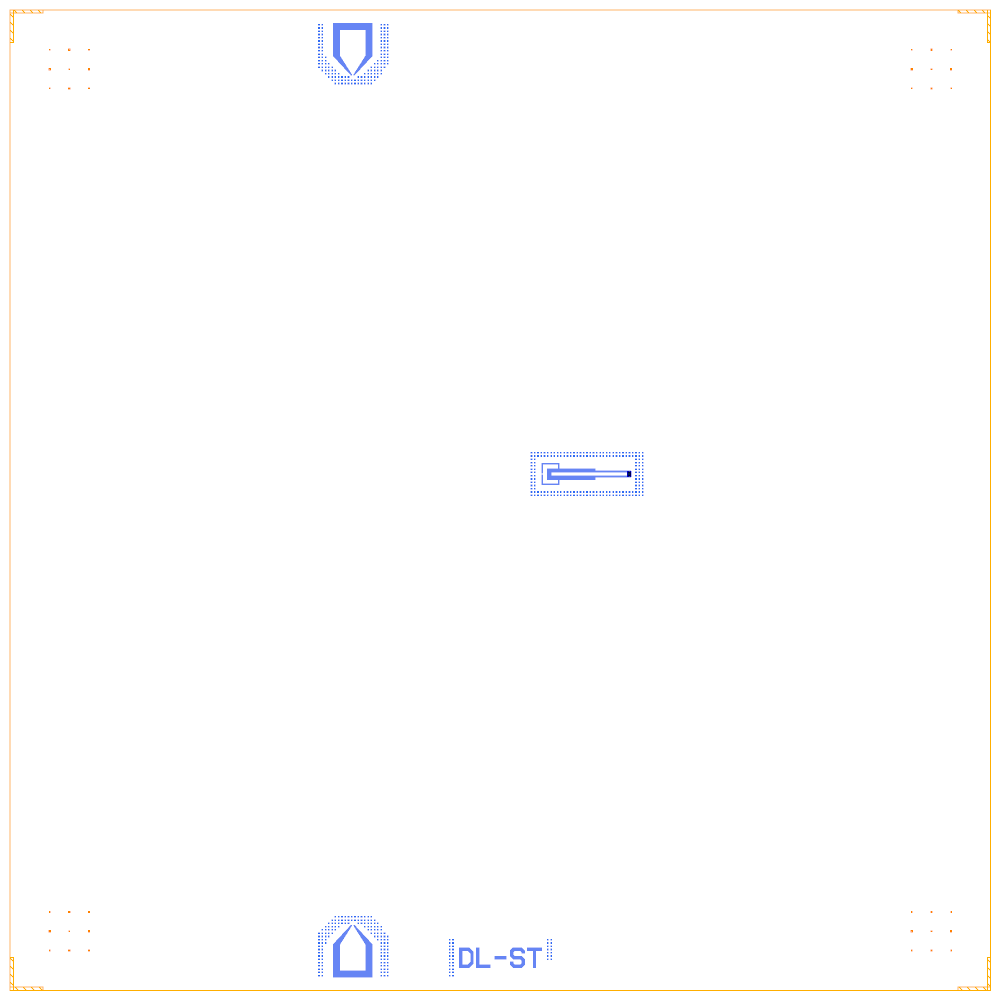

In [6]:
RECT_TRANSMON = dict(fluxline_type="none", arm_length=[12, 298, 12, 298], arm_width=[24] * 4,
                     gap_width=[30, 30, 30, 12], island_r=0,
                     cpl_length=[0, 121, 0], cpl_width=[24, 34, 24], cpl_gap=[84, 84, 84])   # N-arm claw
q = d.add("Q", "Swissmon", at=(2685, 2050), rot=90, junction=JUNCTION, **JJ_PARAMS, **RECT_TRANSMON)
print(q)
snap(d, OUT / "singletransmon_components.png", size=(1000, 1000), width=360);

## 5 · Routes: the feedline and the λ/4 readout

**The feedline** is a straight CPW (PDK default 10/6 µm, bend radius 50 µm) between the pads' ports `a`. With the pads
at the die edges it runs the full die height instead of the source's 2700 µm; a 50 Ω through-line, so its length sets
no frequency.

**The readout** runs from the claw (`Q.cplr1`) through a 500 µm leg to the feedline and ends in `fl.hanger(...)`: a
400 µm section coupled to the feedline across a 5 µm ground strip, shorted at its south end (`direction="backward"`).
`near=(x, y)` centres the coupler at the feedline point nearest (x, y): (897, 1850), where the source has it (y 1650 to
2050). Given by `near=` instead of an arclength `s=` from the feedline start, the coupler does not slide when the pads
(and so the feedline's start) move. The total length is the source's 5000 µm with 5 meander turns (r 50 µm); the
waypoint puts the 500 µm leg's end in front of the claw.

In [7]:
fl = d.route("FL", ps.a, pn.a, r=50)
ro = d.route("R", q.cplr1, fl.hanger(near=(XF + 27, 1850), length=400, side="right", ground_gap=5,
                                     direction="backward", end="short"),
             meander=5000, r=50, nodes=[(XF + 27 + 500, 2050)]).set(meanders=5)
d.targets(Q={"f_q_GHz": 3.370}, R={"f_GHz": 5.244})
d.sim_group("QR", ["Q", "R", "FL"])
rebuild(d)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})

{'FL': 6500.0, 'R': 5000.0}


## 6 · PDK placement: centre the content

`center_in_die(d)` measures the bounding box of every instance and route and shifts them all (instance positions,
route waypoints, hanger `near` points) so that box is centred in the die. The pads sit on the north and south edges,
so the shift is along x only and the pad rule still holds. This run: (+142.5, 0) µm.

shift applied (µm): (142.5, 0.0)


| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| P_S | `BondPad` | s | 100.0 | ✓ |
| P_N | `BondPad` | n | 100.0 | ✓ |

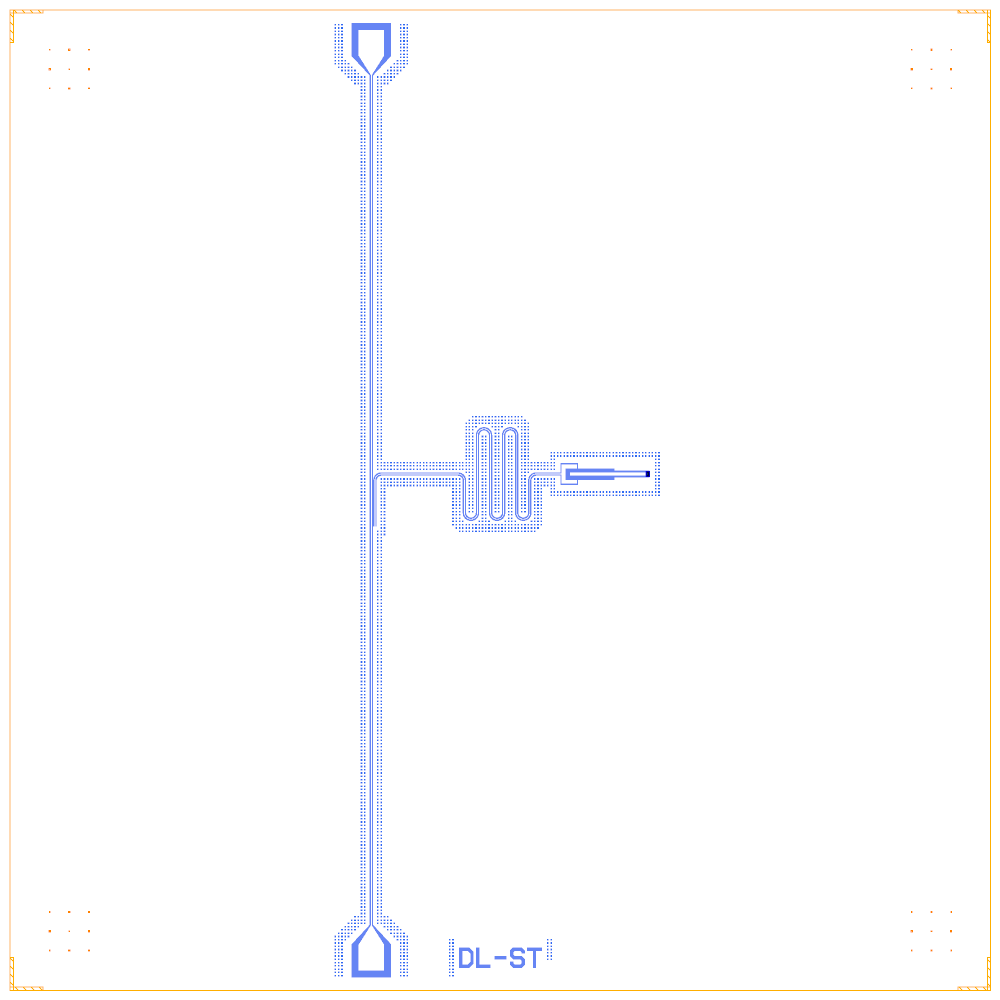

In [8]:
shift = center_in_die(d)
print("shift applied (µm):", shift)
QX, QY = d.data["instances"]["Q"]["place"]["at"]   # the qubit after centring (snapshot boxes below)
XF = XF + shift[0]
rebuild(d)
display(Markdown(pads_md(d)))
snap(d, OUT / "singletransmon_routes.png", size=(1000, 1000), width=360);

## 7 · DRC

`d.drc()` checks connectivity (dangling ports, overlaps, route crossings, netlist opens and shorts) and the PDK
margins. There are three kinds of finding:
- **errors** would make the chip wrong; there must be none;
- **warnings** are worth a look but can be intended: here the stand-in Swissmon's unused couplers `cplr0` / `cplr2`
  (zero length) and its `drive` port (the source qubit has no drive line);
- **PDK design warnings** flag values outside the PDK margins: `pdk_rn` (R_n ≈ 118 kΩ) and `pdk_fq` (the source's
  3.37 GHz target, below 4 GHz). They are reported, never enforced.

Expected (this run): **no errors**; 3 `dangling_port` warnings (`cplr0`, `cplr2`, `drive`); `pdk_rn` (118.4 kΩ) and
`pdk_fq`. No `pad_edge`: both pads sit at 100 µm.

`pdk_report(d)` sums up the PDK checks: cheese source, centring, junction types, design warnings.

In [9]:
rebuild(d)
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 3 warnings · 2 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 3 | Q.cplr0 is not connected (no route or snap) |
| PDK design warning | `pdk_fq` | 1 | Q: f_q target 3.37 GHz is outside the PDK band 4–8 GHz |
| PDK design warning | `pdk_rn` | 1 | Q: junction R_n 118.4 kΩ is outside the PDK window 40–50 kΩ (L_J 17.7222 nH) |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Junction × 1 |
| PDK design warnings | 2 (pdk_rn × 1, pdk_fq × 1) |
| pdk_rn | Q: junction R_n 118.4 kΩ is outside the PDK window 40–50 kΩ (L_J 17.7222 nH) |
| pdk_fq | Q: f_q target 3.37 GHz is outside the PDK band 4–8 GHz |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: the Swissmon's LOM model gives the grounded island node with its
junction to ground and the claw coupler node (C_g to the island); the readout is a λ/4 `TLres` with a `HANGER` (κ) to
the feedline node, which carries the two pads' 50 Ω ports.

In [10]:
lb = d.lom()
show_netlist(lb)
print(lom_summary(lb))

**4 nodes · 8 branches · 0 controls · 2 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `FL` | `FL`, `P_S.pad`, `P_N.pad` |
| `Q` | `Q.island` |
| `Q.cplr1` | `Q.cplr1` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_P_S` | R | `FL` – `gnd` | 50 Ω |
| `Port_P_N` | R | `FL` – `gnd` | 50 Ω |
| `C_Q` | C | `Q` – `gnd` | 65.2 fF |
| `J_Q` | JJ | `Q` – `gnd` | Lj 17.7 nH, Cj 5.7 fF |
| `Cg_Q_cplr1` | C | `Q` – `Q.cplr1` | 3.8 fF |
| `Cc_Q_cplr1` | C | `Q.cplr1` – `gnd` | 74.8 fF |
| `R` | TLres | `Q.cplr1` – `gnd` | lambda/4, 5000 µm, 6.302 GHz |
| `K_R` | HANGER | `Q.cplr1` – `FL` | κ 0.338 MHz (L 400 µm) |

**Unconnected ports:** `Q.cplr0`, `Q.cplr2`

**Builder notes:**

- Q.cplr0: cpl_length 0 (no coupler), its port ends on ground
- Q.cplr2: cpl_length 0 (no coupler), its port ends on ground

{'nodes': 3, 'branches': 8, 'controls': 0, 'unconnected': 2}


## 9 · LOM simulation (whole circuit) vs the Palace eigenmodes

QuCat normal modes of the whole circuit, then the QuTiP dressed values, next to the Palace targets (3.370 GHz qubit,
5.244 GHz resonator). The qubit lands near the 4.05 GHz it was sized for, not at the source's 3.37 GHz; the stand-in
island and the substrate model also shift the resonator. This run: f_q **4.095 GHz**, α −307 MHz; f_r **5.683 GHz**,
8 % above Palace's 5.244 GHz (sapphire εr 10.25 against Palace's anisotropic 9.3 / 11.5, and the claw's loading);
κ 0.224 MHz through the 400 µm coupler; χ −0.71 MHz.

In [11]:
res = simulate_lom(lb, d.design)
display(Markdown(modes_md(res)))
display(Markdown(summary_md(res, {"Q": {"f_q_GHz": 3.370}, "R": {"f_GHz": 5.244}})))

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q | qubit | 4.3728 | 0.000122 | 258.3 | J_Q 1.00 |
| R | resonator | 5.6835 | 0.224 | 0.0 | R 1.00 |

| parameter | LOM (QuTiP) | target |
|---|---|---|
| `Q.f_q_GHz` | 4.0954 | 3.37 |
| `Q.alpha_MHz` | -307.03 | – |
| `R.chi_MHz` | -0.7076 | – |
| `R.f_GHz` | 5.683 | 5.244 |
| `R.kappa_MHz` | 0.22351 | – |

## 10 · FEM: send the job

The sim group `QR` (qubit, readout, feedline) is exported as a Q3D C-matrix job (capacitances by net name) and an
eigenmode/EPR job; the feedline ends in its pads' 50 Ω ports, as the Palace model's lumped ports. Job folders are
self-contained (`build/jobs/<design>_<group>_<analysis>`); exporting again replaces a folder, results included.
Simulation exports never carry cheese.

`RUN_FEM = False` only exports. With `RUN_FEM = True` and AEDT 2024 R1 (or newer) on this machine, `send_fem_jobs`
solves each job in a **new batch, non-graphical AEDT** (`solve_job`); an AEDT window you have open is never touched. On another
machine: `qcc hfss solve build/jobs/<job>`.

In [12]:
RUN_FEM = False                                  # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
DESIGN = d.save(OUT / "singletransmon.json")
jobs = export_sims(DESIGN, ["QR"])
jobs_eig = export_sims(DESIGN, ["QR"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))
if RUN_FEM:
    send_fem_jobs(DESIGN, ["QR"], analyses=["q3d_cmatrix", "eigenmode_epr"], run=True)

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| QR | `build/jobs/singletransmon_QR_q3d_cmatrix` | 1 · junction · `Q.junction`<br>2 · waveguide · `Q.cplr1`<br>3 · lumped · `P_N.pad`<br>4 · lumped · `P_S.pad` | `Q.island`, `Q.cplr1`, `P_N.pad` |
| QR | `build/jobs/singletransmon_QR_eigenmode_epr` | 1 · junction · `Q.junction`<br>2 · lumped · `P_N.pad`<br>3 · lumped · `P_S.pad` | `Q.island`, `P_N.pad` |

## 11 · Bring the results back

When a job has results (`build/jobs/<job>/results/results.json`), `fill(model, design, job)` puts the extracted
capacitances into the LOM by net name, next to the estimates, and the LOM can be simulated again on them. Until a
solve has run, the cell says what would appear.

In [13]:
filled, md = fem_back(lb.model, DESIGN, {**{f"{g} · q3d": v for g, v in jobs.items()},
                                         **{f"{g} · eigenmode": v for g, v in jobs_eig.items()}})
display(Markdown(md))

No FEM results yet for QR · q3d, QR · eigenmode: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Iterate: change one property and re-simulate

The LOM is cheap, so a design change can be checked in seconds. Here the claw is lengthened from 121 to 150 µm: it
wraps more of the island, so the coupling capacitance, g and χ grow, and the qubit moves down a little (more C_Σ). This run: χ −0.708 → −1.109 MHz, f_q 4.095 → 4.070 GHz, and the readout
moves down too (5.683 → 5.602 GHz: the longer claw loads its open end).
`design_copy` opens a second, non-live Designer on the saved design, so the design file stays as it is.

In [14]:
d2 = design_copy(DESIGN)
d2["Q"].set(cpl_length=[0, 150, 0])
res2 = simulate_lom(d2.lom(), d2.design)
display(Markdown(params_delta_md(res, res2)))

| parameter | before | after | Δ |
|---|---|---|---|
| `Q.f_q_GHz` | 4.0954 | 4.0697 | -0.02575 |
| `Q.alpha_MHz` | -307.03 | -302.17 | +4.857 |
| `R.chi_MHz` | -0.7076 | -1.1092 | -0.4016 |
| `R.f_GHz` | 5.683 | 5.6022 | -0.08082 |
| `R.kappa_MHz` | 0.22351 | 0.2109 | -0.01261 |

## 13 · Build and export

- **Design file:** `d.save(...)` wrote `examples/designs/devicelayout/singletransmon.json` (step 10); `Designer.load`
  reopens it.
- **Fab mask:** `export_fab` writes only the PDK fab layers (negative mask): the frame (100/0, 1000/0, 1001/0), the
  base etch 1/0 with its cheese and the 3/0 keep-out, the trilayer junction (fingers 2/0 + 4/0, spacer 50/0 with the
  51–53/0 gradient), with corner rounding. The cheese is the PDK band the build drew (the source has none).
- **Simulation export options:** `build_simulation(design, group, analysis, airbridges=True)` keeps airbridges in a
  FEM export (none are drawn here, see the summary); cheese is never exported.
- **Command line:** `qcc build examples/designs/devicelayout/singletransmon.json` (layout + sidecar), `qcc design drc
  …`, `qcc mask …` (fab file), `qcc sim build … -g QR -a q3d_cmatrix`, `qcc hfss solve build/jobs/<job>`.

In [15]:
rebuild(d)
display(Markdown(fab_layers_md(d, cheese=True, rounding=True)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 2204 |
| 2/0 | JJ_STRAIGHT | 1 |
| 3/0 | M3 | 2203 |
| 4/0 | JJ_BENT | 1 |
| 50/0 | HSQ | 2 |
| 51/0 | SPACER_1 | 2 |
| 52/0 | SPACER_2 | 2 |
| 53/0 | SPACER_3 | 2 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 2197 holes on the mask.

→ `build/singletransmon_fab.oas`

## 14 · Snapshots (headless KLayout)

The full die (compare the DeviceLayout mesh figure, which shows the same layout rotated by −90°: there the feedline is
2700 µm, here it runs between pads at the die edges); the island with the claw; its trilayer junction; the coupled
section; the fab mask round the qubit and the coupler (the PDK band's 5 µm holes along the 3/0 keep-outs, on 1/0 and
3/0, the junction layers); the die frame's south-west corner (PDK dicing L on 1000/0, 3 × 3 alignment grid on
1001/0).

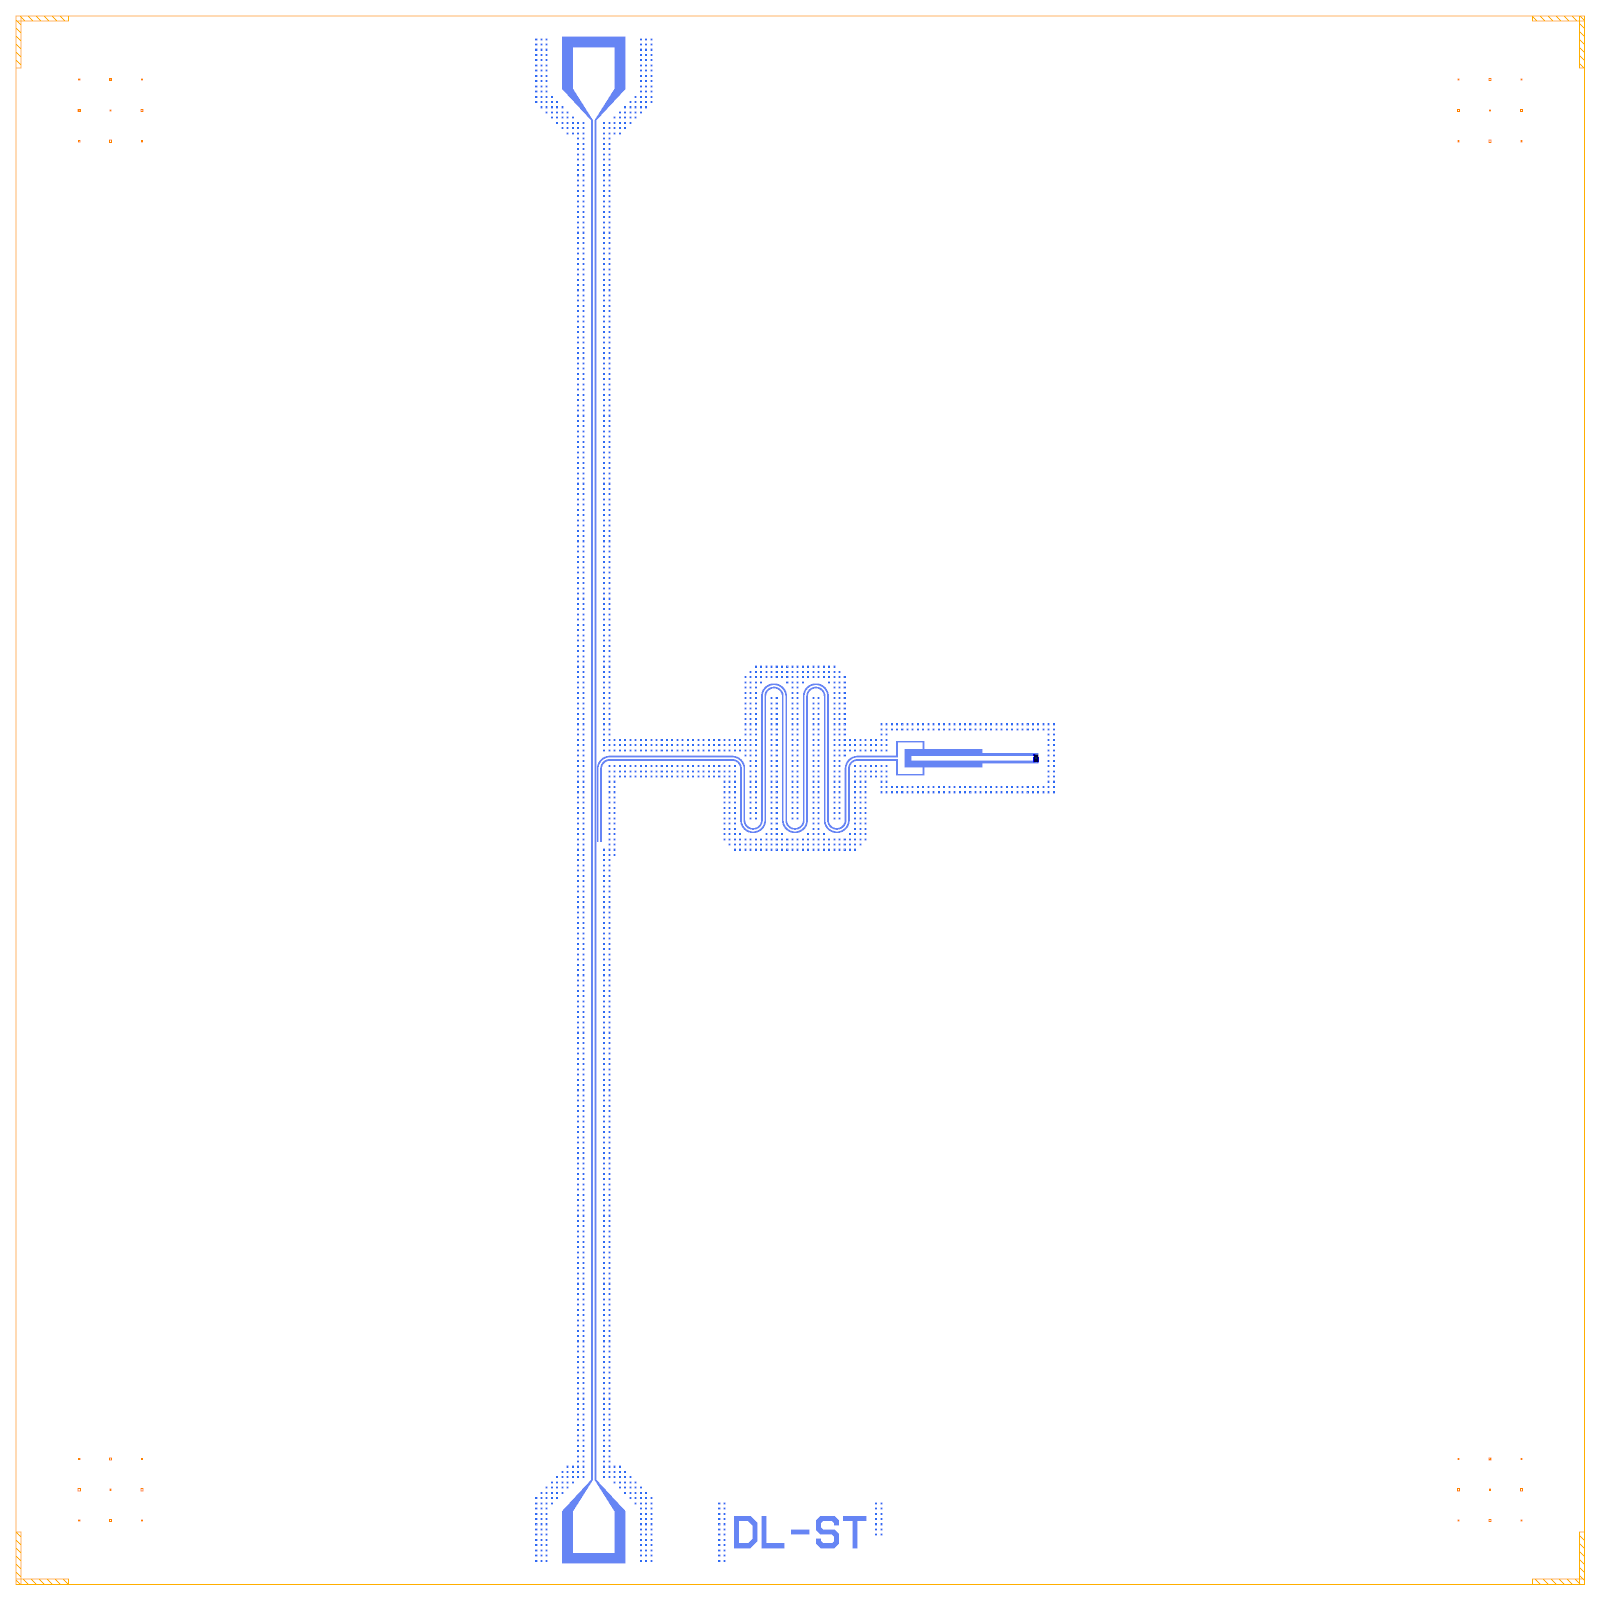

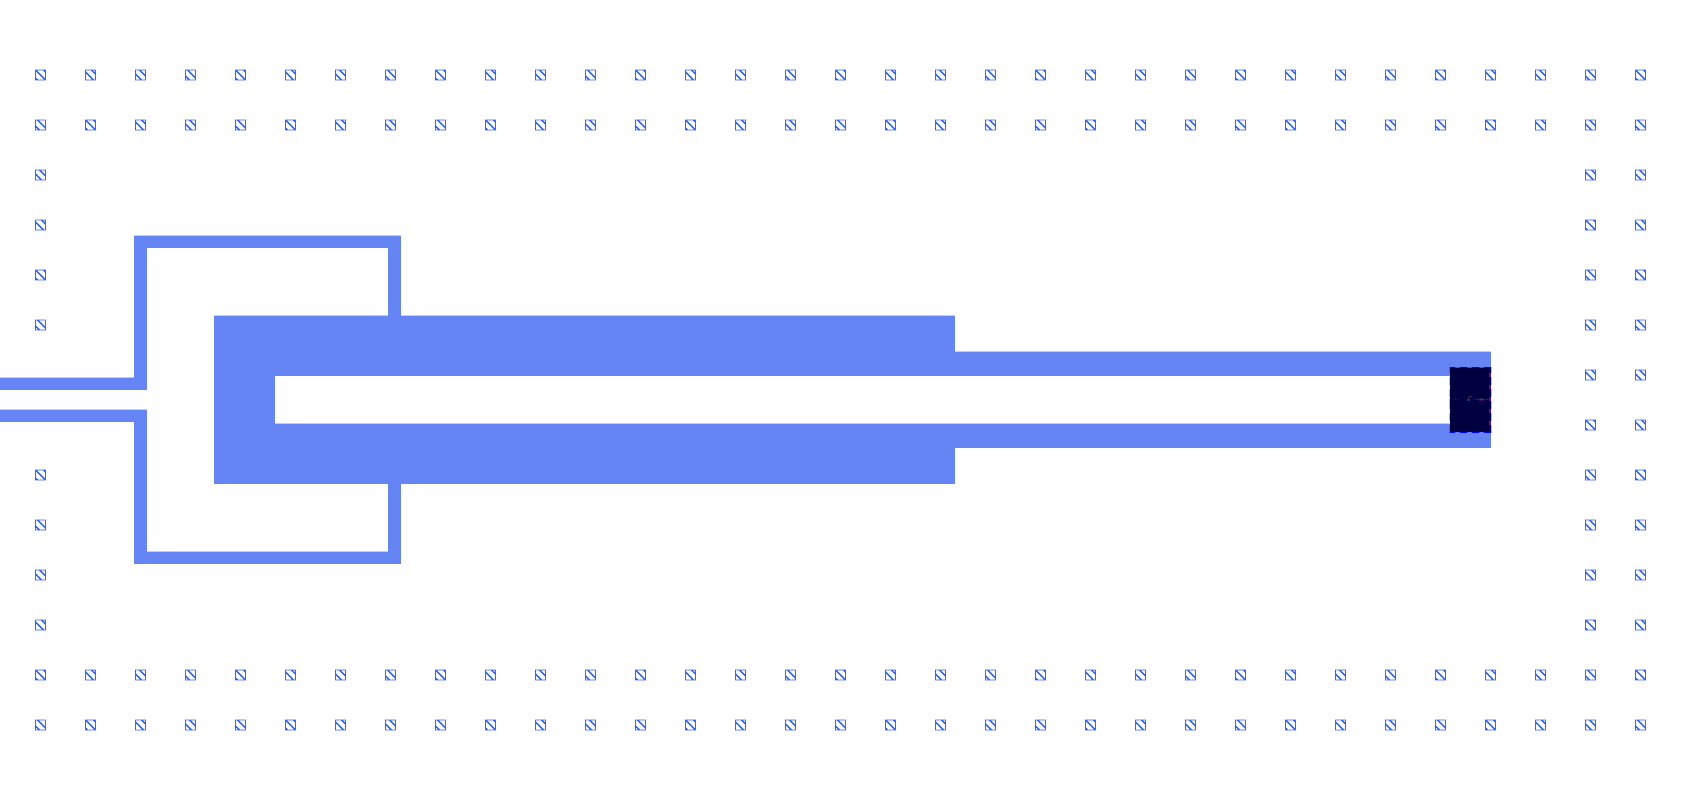

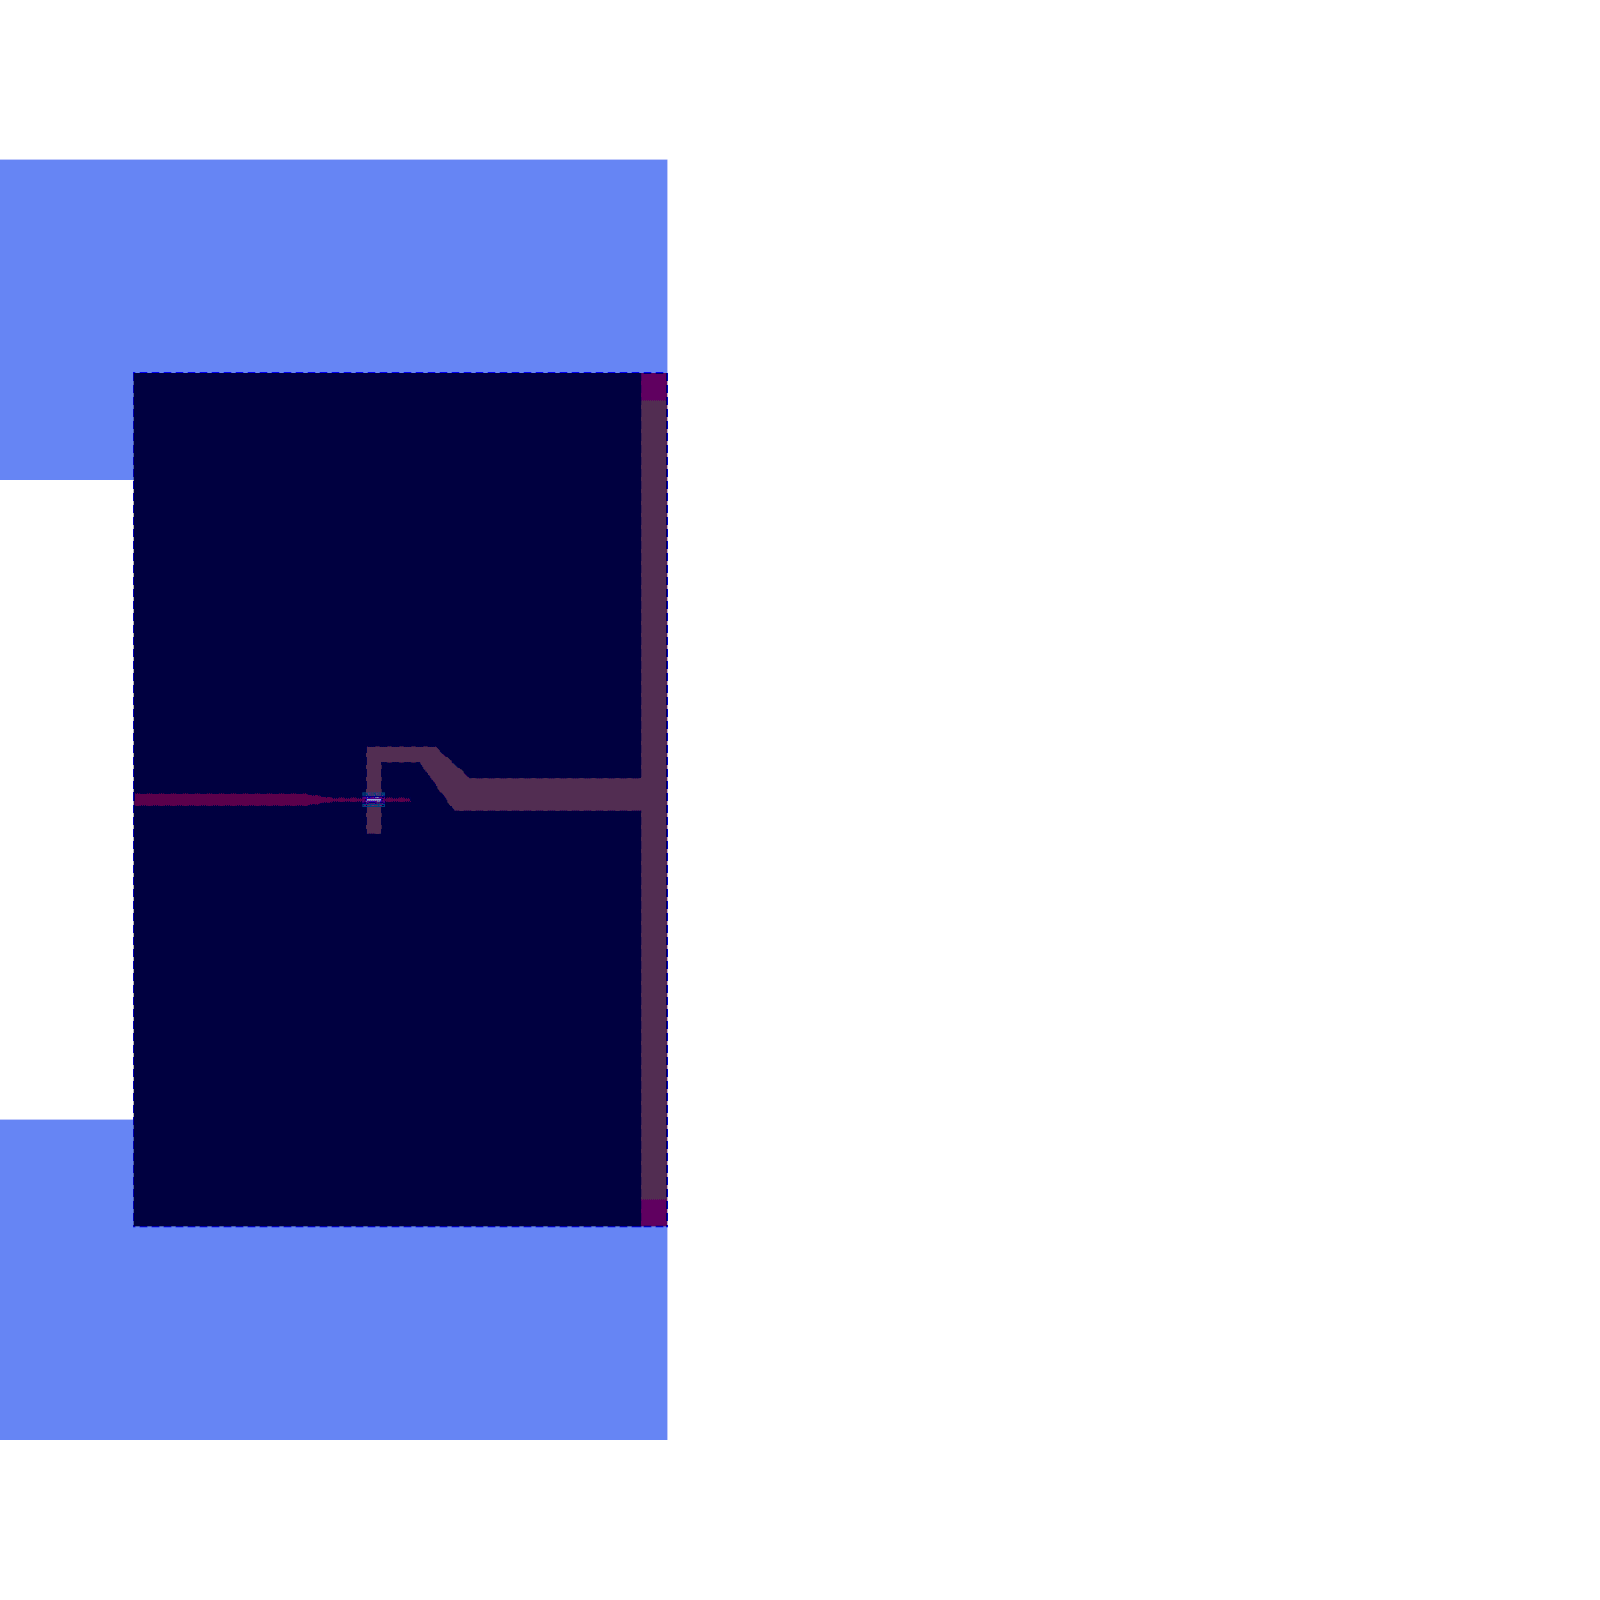

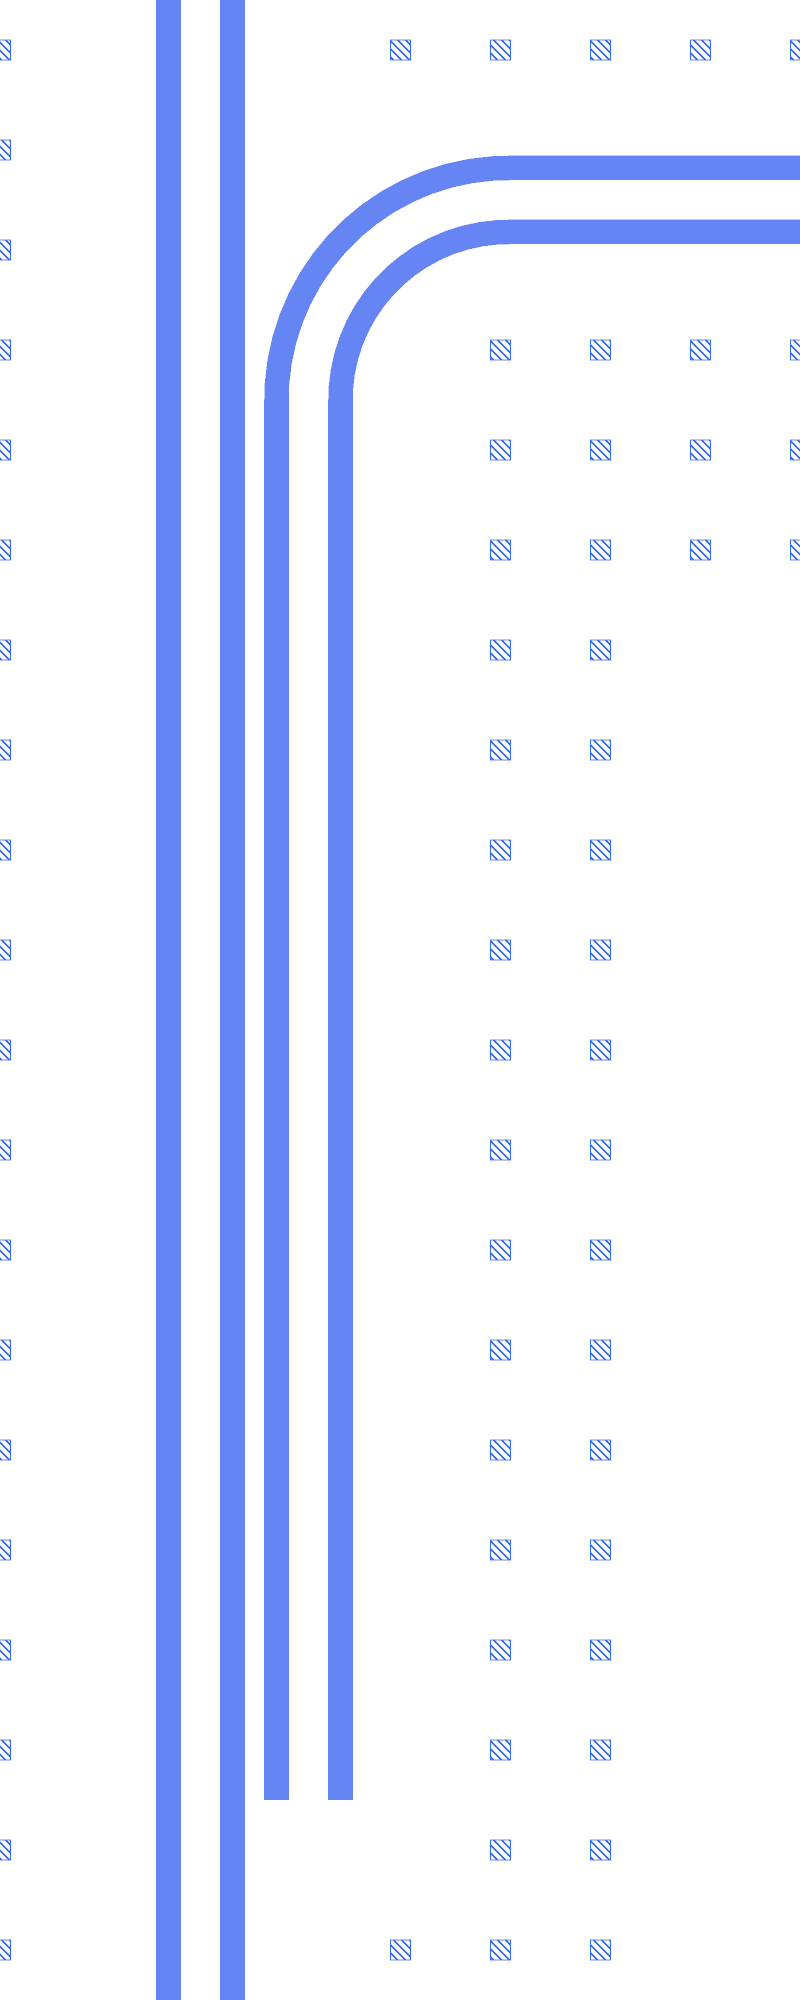

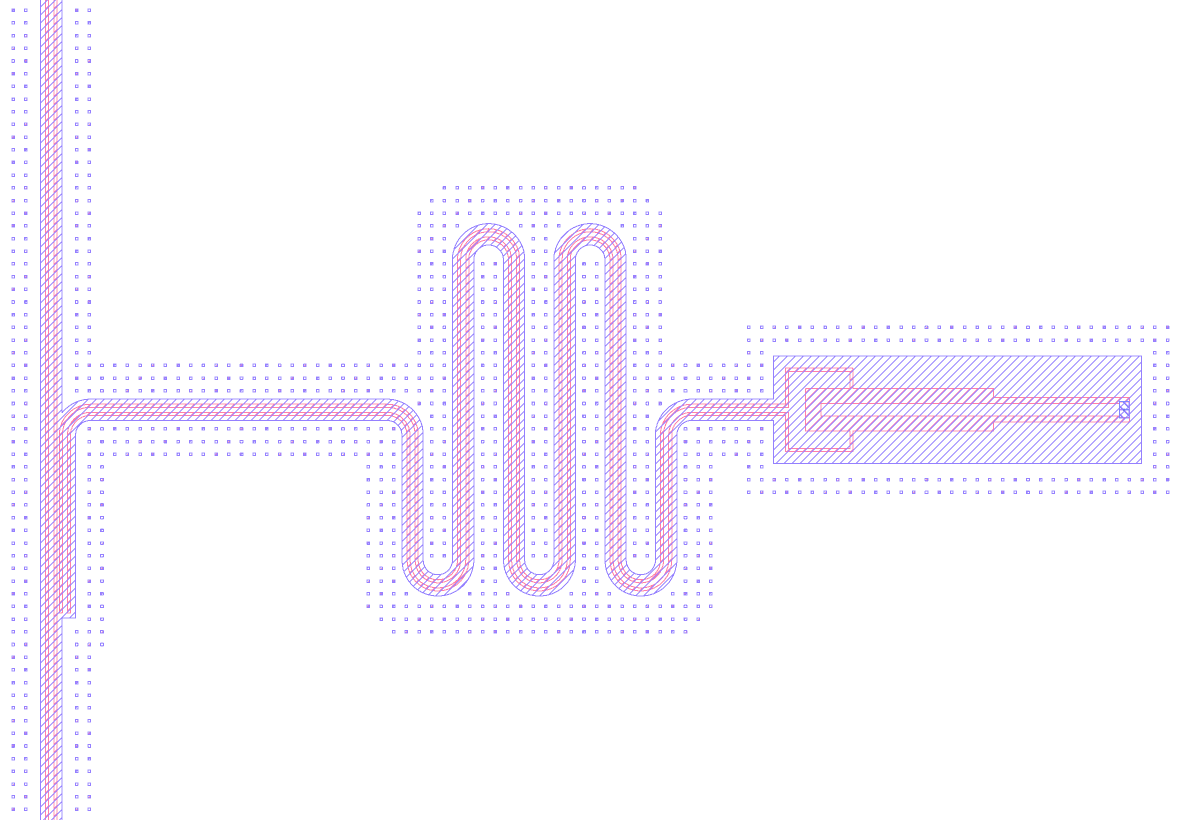

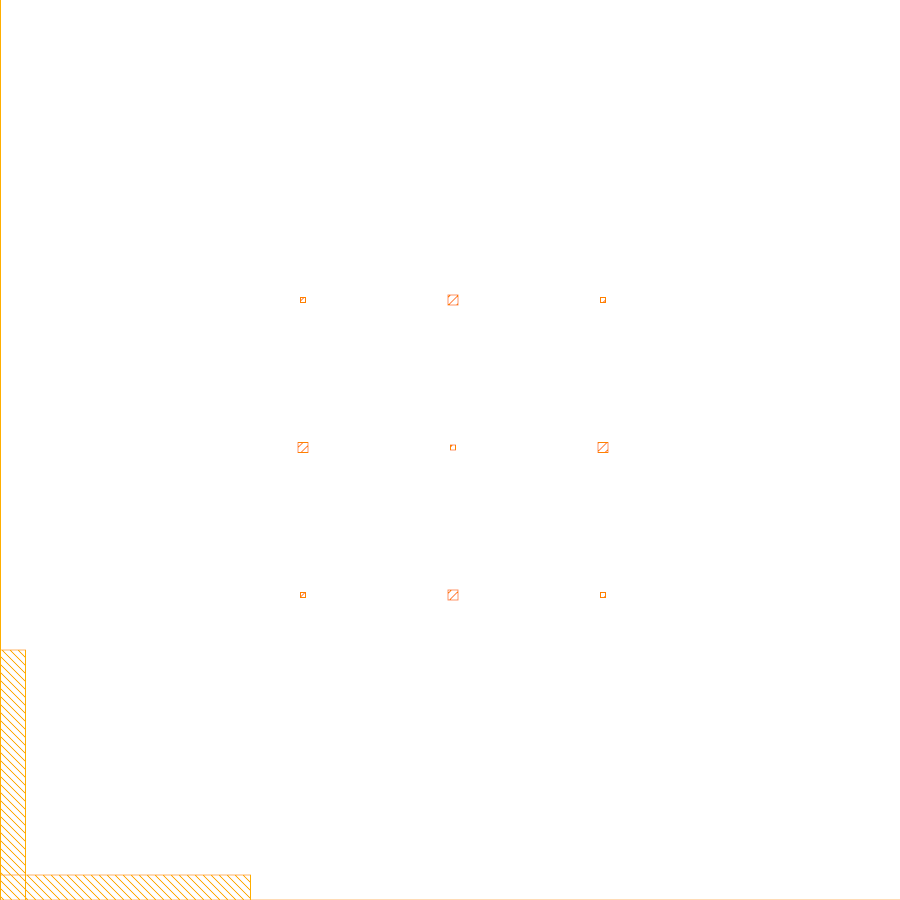

In [16]:
snap(d, OUT / "singletransmon.png", size=(1600, 1600))
snap(d, OUT / "singletransmon_qubit.png", box=(QX - 435, QY - 200, QX + 415, QY + 200), size=(1700, 800), width=560)
snap(d, OUT / "singletransmon_jj.png", box=(QX + 285, QY - 30, QX + 345, QY + 30), width=300)
snap(d, OUT / "singletransmon_coupler.png", box=(XF - 50, 1600, XF + 150, 2100), size=(800, 2000), width=200)
snap_file(Path("build") / "singletransmon_fab.oas", OUT / "singletransmon_cheese.png",
          box=(XF - 100, QY - 450, QX + 450, QY + 450), size=(1200, 820), width=480)
snap(d, OUT / "singletransmon_frame.png", box=(-1750, -1900, -850, -1000), size=(900, 900), width=300);

## 15 · Summary

- **Matches the source:** CPW 10/6 µm and 50 µm bends, the 400 µm coupled section with its 5 µm ground strip in the
  same place, the 5000 µm readout with 5 meander turns, the claw and island geometry, the sim group and the Palace
  targets.
- **Changed by the PDK:** the 7.5 mm die with the frame and device ID, sapphire εr 10.25, a Quantcore trilayer junction
  (sized for 4.05 GHz), the two pads 100 µm from the die edges (the feedline now crosses the die), the content
  centred (+142.5 µm in x), the PDK band cheese (2197 holes in the mask).
- **Substituted:** a KQC `Swissmon` for the rectangle island (no 2 µm claw shield); the router's KQC meander (the
  source keeps a 428 µm straight arm before the claw); no airbridges (KQC's `airbridges="auto"` put bridges across the
  coupled section whose pads landed on the neighbouring line, a short).
- **Open PDK design warnings:** `pdk_rn` on Q (R_n 118.4 kΩ) and `pdk_fq` on the 3.37 GHz target. Flagged, not
  retuned. LOM: f_q 4.095 GHz (sized for 4.05), f_r 5.683 GHz against Palace's 5.244 GHz.
- **Open:** the FEM jobs are exported, not solved (`RUN_FEM = False`).